# EXP-005 — Random Forest mặc định
Người thực hiện:   Mai  
Ngày chạy: 16/11/2026  lần 1  
Lần 2: 18/11/2026  
Lần 3:19/11/2026  
Lần 4: 22/11/2026  


## Mục tiêu và giả thuyết

Mô hình Random Forest (RF) để kiểm tra khả năng nhận diện stress ở những người chưa từng xuất hiện trong dữ liệu huấn luyện. 
Kỳ vọng RF sẽ cho kết quả Macro-F1 và Balanced Accuracy cao hơn mô hình Dummy nhờ khả năng học từ 68 đặc trưng sinh lý. Qua đó, đánh giá xem RF có phù hợp để sử dụng trong bản demo đọc dữ liệu từ file CSV hay không

## Dữ liệu và cách đánh giá

Bộ dữ liệu physiological68 gồm 6.189 mẫu, 68 đặc trưng sinh lý và 15 người tham gia. Nhóm sử dụng phương pháp LOSO, mỗi lần lấy dữ liệu của 1 người để kiểm tra và 14 người còn lại để huấn luyện. Quá trình này lặp lại 15 lần.

Thí nghiệm gồm hai bài toán: phân loại Stress và Non-stress; phân loại Baseline, Stress và Amusement.

Mô hình sử dụng là Random Forest với tham số mặc định. Dữ liệu bị thiếu được thay bằng giá trị trung vị, tính từ tập huấn luyện của từng lần chạy. Nhóm không điều chỉnh tham số, cân bằng lớp hay chọn lọc đặc trưng. Thông tin SHA-256 và đường dẫn schema được lưu trong `config.yaml`.

In [1]:
from pathlib import Path
import json

import pandas as pd
import yaml

here = Path.cwd()
repo = next(path for path in (here, *here.parents) if (path / "scripts/run_g3_baselines.py").is_file())
experiment = repo / "experiments/01_baselines/EXP-005_RF"
config = yaml.safe_load((experiment / "config.yaml").read_text(encoding="utf-8"))
output = repo / config["output_dir"]
data = pd.read_csv(repo / config["features"], usecols=["subject_id", "label_original"])
print(f"{len(data)} cửa sổ, {data['subject_id'].nunique()} người")
display(data["label_original"].map({1: "Baseline", 2: "Stress", 3: "Amusement"}).value_counts())


6189 cửa sổ, 15 người


label_original
Baseline     3370
Stress       1848
Amusement     971
Name: count, dtype: int64

## Thiết lập thực nghiệm

Thí nghiệm sử dụng runner G3 với cấu hình `config.yaml`, seed 42 và thư mục kết quả riêng `outputs/exp005_rf_full`. Cả hai bài toán dùng cùng cách chia dữ liệu. Tham số RF được giữ cố định qua các fold.

## Lần 1 — Phân tích kết quả G3

Kết quả lịch sử của Random Forest mặc định được lưu trong `results.csv`, gồm 15 người cho mỗi bài toán. Phần nhận xét G3 bên dưới ghi lại kết quả đối chứng của lần này.

## Kết quả theo người tham gia

Macro-F1 là trung bình F1 của các lớp và Balanced Accuracy là trung bình recall của các lớp. Hai chỉ số được tính riêng cho từng người trong tập test. Kết quả của mỗi bài toán được tổng hợp bằng trung bình và độ lệch chuẩn mẫu qua 15 người.

Bảng `results.csv` lưu 30 dòng RF từ `reports/g3_group/metrics_by_subject.csv` (kết quả lịch sử G3). Điểm của lần 2 được trình bày ở mục riêng bên dưới.

In [2]:
g3_source = repo / "reports/g3_group/metrics_by_subject.csv"
g3 = pd.read_csv(g3_source)
results = pd.read_csv(experiment / "results.csv")
metrics = ["macro_f1", "balanced_accuracy"]

keys = ["task", "subject_id"]
assert len(results) == 30 and not results.duplicated(keys).any()
assert set(results["model"]) == {"rf"}
assert set(results["task"]) == {"binary", "multiclass"}
assert results.groupby("task")["subject_id"].apply(
    lambda ids: set(ids) == set(config["expected_subjects"])
).all()

print("Trạng thái: historical (phân tích kết quả G3)")
print("Nguồn điểm RF: results.csv")
display(results[keys + metrics].sort_values(keys).round(4))
display(results.groupby("task")[metrics].agg(["mean", "std"]).round(4))


Trạng thái: historical (phân tích kết quả G3)
Nguồn điểm RF: results.csv


,task,subject_id,macro_f1,balanced_accuracy
15,binary,S10,0.5017,0.6409
16,binary,S11,0.9832,0.9897
17,binary,S13,0.6991,0.7884
18,binary,S14,0.9855,0.9802
19,binary,S15,0.6856,0.6667
20,binary,S16,1.0000,1.0000
21,binary,S17,0.9028,0.8840
22,binary,S2,0.9177,0.8947
23,binary,S3,0.9366,0.9153
24,binary,S4,1.0000,1.0000


macro_f1         balanced_accuracy        
               mean     std              mean     std
task                                                 
binary       0.8735  0.1440            0.8865  0.1143
multiclass   0.6480  0.1297            0.6700  0.1204

## Đối chiếu với các mô hình cơ sở

Phần này so sánh RF với Dummy, LR, KNN, SVM và MLP trên cùng 15 người và tách riêng hai bài toán. Điểm RF lấy từ nguồn ghi ở phần kết quả. Điểm của năm mô hình đối chiếu lấy từ bảng G3. Phần chênh lệch theo từng người dùng Dummy làm mốc vì Dummy luôn dự đoán lớp phổ biến nhất trong tập train.

macro_f1  balanced_accuracy
task       model                               
binary     Dummy      0.4123             0.5000
           KNN        0.7258             0.7541
           LR         0.8103             0.8304
           MLP        0.7986             0.8225
           RF (G3)    0.8735             0.8865
           SVM        0.8424             0.8663
multiclass Dummy      0.2350             0.3333
           KNN        0.5555             0.5753
           LR         0.5894             0.6315
           MLP        0.6462             0.6815
           RF (G3)    0.6480             0.6700
           SVM        0.6177             0.6595

,macro_f1_rf,macro_f1_dummy,macro_f1_delta,balanced_accuracy_rf,balanced_accuracy_dummy,balanced_accuracy_delta
task,,,,,,
binary,0.8735,0.4123,0.4612,0.8865,0.5000,0.3865
multiclass,0.6480,0.2350,0.4129,0.6700,0.3333,0.3367


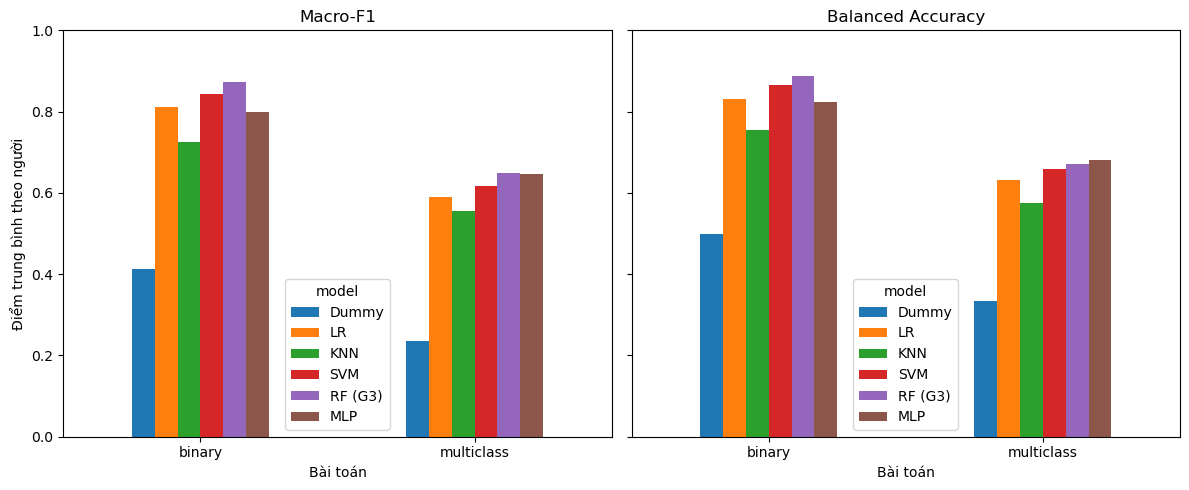

In [3]:
import matplotlib.pyplot as plt

dummy = g3.loc[g3["model"].eq("dummy")]
rf_label = "RF (G3)"
model_labels = {"dummy": "Dummy", "lr": "LR", "knn": "KNN", "svm": "SVM", "rf": rf_label, "mlp": "MLP"}
baseline_rows = pd.concat([g3.loc[g3["model"].ne("rf")], results], ignore_index=True)
model_scores = baseline_rows.groupby(["task", "model"])[metrics].mean()
display(model_scores.rename(index=model_labels, level="model").round(4))
keys = ["task", "subject_id"]
paired = results.merge(dummy[keys + metrics], on=keys, suffixes=("_rf", "_dummy"), validate="one_to_one")
assert len(paired) == 30

for metric in metrics:
    paired[f"{metric}_delta"] = paired[f"{metric}_rf"] - paired[f"{metric}_dummy"]

columns = [f"{metric}_{suffix}" for metric in metrics for suffix in ("rf", "dummy", "delta")]
comparison = paired.groupby("task")[columns].mean()
display(comparison.round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
for ax, metric, title in zip(axes, metrics, ["Macro-F1", "Balanced Accuracy"]):
    scores = model_scores[metric].unstack("model").reindex(columns=list(model_labels))
    scores.rename(columns=model_labels).plot.bar(ax=ax, rot=0, title=title)
    ax.set_ylim(0, 1)
    ax.set_xlabel("Bài toán")
axes[0].set_ylabel("Điểm trung bình theo người")
fig.tight_layout()
figures = experiment / "figures"
figures.mkdir(exist_ok=True)
fig.savefig(figures / "rf_vs_baselines_g3.png", dpi=150)
plt.show()


## Nhận xét và kết luận

Trong kết quả lịch sử G3, RF đạt Macro-F1 **0,8735** và Balanced Accuracy **0,8865** ở bài toán nhị phân. Với ba lớp, hai điểm lần lượt là **0,6480** và **0,6700**. RF vượt Dummy trên cả hai chỉ số ở cả hai bài toán.

RF dẫn đầu các mô hình cơ sở G3 ở cả hai chỉ số trong bài toán nhị phân. Với ba lớp, RF có Macro-F1 cao nhất, còn MLP có Balanced Accuracy cao hơn RF (0,6815 so với 0,6700). Điểm trung bình cho thấy RF là ứng viên hợp lý cho demo nhị phân trên dữ liệu physiological68. Chênh lệch giữa các mô hình ở bài toán ba lớp cần được xem cùng độ biến thiên giữa người tham gia. Thí nghiệm này chưa đo độ trễ suy luận.

Kết quả G3 là mốc tham chiếu lịch sử. Cell dưới tổng hợp kết quả từ nguồn RF đang được phân tích và cho biết số người có Macro-F1 cải thiện so với Dummy.

In [4]:
from IPython.display import Markdown

task_names = {"binary": "Nhị phân", "multiclass": "Ba lớp"}
source_name = "kết quả lịch sử G3"
lines = [f"**Kết quả từ {source_name}**"]
for task, folds in paired.groupby("task"):
    scores = comparison.loc[task]
    improved = folds["macro_f1_delta"].gt(0).sum()
    weakest = folds.loc[folds["macro_f1_rf"].idxmin()]
    lines.append(
        f"- **{task_names[task]}** — Macro-F1 {scores['macro_f1_rf']:.4f} "
        f"(chênh lệch so với Dummy {scores['macro_f1_delta']:+.4f}), "
        f"Balanced Accuracy {scores['balanced_accuracy_rf']:.4f} "
        f"(chênh lệch {scores['balanced_accuracy_delta']:+.4f}). "
        f"Macro-F1 cao hơn Dummy ở {improved}/{len(folds)} người. "
        f"Fold có Macro-F1 RF thấp nhất là {weakest['subject_id']} "
        f"({weakest['macro_f1_rf']:.4f})."
    )
display(Markdown("\n".join(lines)))


**Kết quả từ kết quả lịch sử G3**
- **Nhị phân** — Macro-F1 0.8735 (chênh lệch so với Dummy +0.4612), Balanced Accuracy 0.8865 (chênh lệch +0.3865). Macro-F1 cao hơn Dummy ở 15/15 người. Fold có Macro-F1 RF thấp nhất là S10 (0.5017).
- **Ba lớp** — Macro-F1 0.6480 (chênh lệch so với Dummy +0.4129), Balanced Accuracy 0.6700 (chênh lệch +0.3367). Macro-F1 cao hơn Dummy ở 15/15 người. Fold có Macro-F1 RF thấp nhất là S10 (0.3649).

## Lần 2 — Kiểm tra chạy lại và đối chiếu kết quả

Sử dụng cùng cấu hình và giao thức LOSO như G3. Runner dùng thư mục riêng `outputs/exp005_rf_full/` và có thể tiếp tục từ các fold hợp lệ đã lưu. Đối chiếu Macro-F1 và Balanced Accuracy theo từng bài toán và từng người test với kết quả G3.

**Hai metric khớp kết quả G3 ở đủ 30 fold.**

In [5]:
import subprocess

command = [
    str(repo / ".venv-g1/Scripts/python.exe"),
    "-X", "utf8", "scripts/run_g3_baselines.py",
    "--config", str(experiment / "config.yaml"),
    "--resume",
]
print((experiment / "config.yaml").read_text(encoding="utf-8"))

subprocess.run(command, cwd=repo, check=True)


protocol: g3_defaults_physiological68_v1
features: data/features/g2_physiological68_group15_20261107/all_subjects.csv
schema: data/features/g2_physiological68_group15_20261107/feature_schema.json
feature_version: physiological_68_v1
feature_sha256: 2f2fddd678f333a800f2869d2e78b407934b2c3492190ed70e28d8a9107fd8ba
output_dir: outputs/exp005_rf_full
source_paths:
- src/wesad/data.py
- src/wesad/evaluation.py
- src/wesad/models.py
- src/wesad/utils.py
- src/wesad/g3.py
- scripts/run_g3_baselines.py
- scripts/merge_g3_predictions.py
source_hash_normalization: LF
expected_subjects:
- S2
- S3
- S4
- S5
- S6
- S7
- S8
- S9
- S10
- S11
- S13
- S14
- S15
- S16
- S17
models:
- rf
tasks:
- multiclass
- binary
seed: 42
sensor_set: combined_physiological68
normalization: global_train
balance: false
nested: false
zero_division: 0
missing_train_class: error
missing_test_class: fixed_labels_for_macro_f1_observed_classes_for_balanced_accuracy
model_params:
  rf:
    random_state: 42
    n_jobs: 1



CompletedProcess(args=['d:\\mayhoc\\Machine-learning\\wesad-stress-detection\\.venv-g1\\Scripts\\python.exe', '-X', 'utf8', 'scripts/run_g3_baselines.py', '--config', 'd:\\mayhoc\\Machine-learning\\wesad-stress-detection\\experiments\\01_baselines\\EXP-005_RF\\config.yaml', '--resume'], returncode=0)

In [6]:
import numpy as np

verification = json.loads((output / "verification.json").read_text(encoding="utf-8"))
assert verification["status"] == "passed" and verification["scope"] == "main"
assert verification["models"] == ["rf"] and verification["n_folds"] == 30
assert verification["n_predictions"] == 12378
assert verification["data_sha256"] == config["feature_sha256"]

rerun_results = pd.read_csv(output / "verified_metrics_by_subject.csv")
assert len(rerun_results) == len(results)
assert set(rerun_results["model"]) == {"rf"}
matched = results[keys + metrics].merge(
    rerun_results[keys + metrics], on=keys, suffixes=("_g3", "_rerun"),
    validate="one_to_one",
)
assert len(matched) == len(results) == 30

print("Trạng thái: rerun (đã xác minh 30 fold)")
display(rerun_results.groupby("task")[metrics].agg(["mean", "std"]).round(4))

for metric in metrics:
    matched[f"{metric}_delta"] = matched[f"{metric}_rerun"] - matched[f"{metric}_g3"]

from IPython.display import Markdown

display(Markdown("### Đối chiếu Lần 1 và Lần 2"))

summary_columns = [
    f"{metric}_{suffix}"
    for metric in metrics
    for suffix in ("g3", "rerun", "delta")
]
comparison_summary = matched.groupby("task")[summary_columns].mean()
comparison_summary.columns = pd.MultiIndex.from_product([
    ["Macro-F1", "Balanced Accuracy"],
    ["Lần 1 (G3)", "Lần 2", "Chênh lệch"],
])
display(comparison_summary.rename(index={"binary": "Nhị phân", "multiclass": "Ba lớp"}).round(4))

delta_columns = [f"{metric}_delta" for metric in metrics]
different = ~np.isclose(matched[delta_columns], 0, atol=1e-10, rtol=0).all(axis=1)
if different.any():
    print(f"Số fold có điểm khác G3: {different.sum()}/30")
    display(matched.loc[different, keys + delta_columns])
else:
    print("Hai metric khớp kết quả G3 ở đủ 30 fold.")

rerun_file = experiment / "results_rerun.csv"
if not rerun_file.exists():
    rerun_results.to_csv(rerun_file, index=False, mode="x")
    print("Bảng kết quả:", rerun_file.name)
elif pd.read_csv(rerun_file).equals(rerun_results):
    print("Đã có bảng kết quả:", rerun_file.name)
else:
    print("Bảng CSV của lượt này:", output / "verified_metrics_by_subject.csv")

Trạng thái: rerun (đã xác minh 30 fold)


macro_f1         balanced_accuracy        
               mean     std              mean     std
task                                                 
binary       0.8735  0.1440            0.8865  0.1143
multiclass   0.6480  0.1297            0.6700  0.1204

### Đối chiếu Lần 1 và Lần 2

Macro-F1                    Balanced Accuracy                   
         Lần 1 (G3)   Lần 2 Chênh lệch        Lần 1 (G3)   Lần 2 Chênh lệch
task                                                                       
Nhị phân     0.8735  0.8735        0.0            0.8865  0.8865        0.0
Ba lớp       0.6480  0.6480        0.0            0.6700  0.6700        0.0

Hai metric khớp kết quả G3 ở đủ 30 fold.
Đã có bảng kết quả: results_rerun.csv


## Bổ sung — Cấu hình A, A+B, A+B+C và điểm train–test  
## 19/11/2026  

Ba cấu hình được cố định trước khi đánh giá, tích lũy từng thay đổi:

| Cấu hình | Số cây | Độ sâu tối đa | Đặc trưng mỗi lần chia |
|---|---:|---|---|
| A | 20 | Không giới hạn | sqrt |
| A+B | 20 | 8 | sqrt |
| A+B+C | 20 | 8 | 0,25 |

A dùng RF 20 cây. B thêm giới hạn độ sâu 8. C đặt tỷ lệ đặc trưng xét ở mỗi lần chia nhánh là 0,25. Random seed là 42. Số cây được giảm để phù hợp tài nguyên máy; kết quả chỉ mô tả các cấu hình nhỏ này và chưa đủ để kết luận về RF có nhiều cây hơn.

Mỗi cấu hình được đánh giá đủ 15 lượt LOSO cho binary và multiclass, tổng cộng 90 lượt fit. Mỗi lượt dùng 14 người train và một người test. Imputer được fit trên train. Điểm train và test được tính từ cùng mô hình đã fit; bảng và biểu đồ lấy trung bình theo người. Chênh lệch train–test giúp xem xét khả năng khái quát hóa.

Đây là khảo sát cấu hình cố định bổ sung cho EXP-005. EXP-009 thực hiện chọn tham số bằng inner CV. Baseline 100 cây ở Lần 1 và Lần 2 được trình bày ở phần trước.

Nguồn cấu hình: [config_train_test.yaml](config_train_test.yaml). Kết quả chạy nhẹ lưu tại `outputs/exp005_rf_cumulative_train_test_light20`, bảng xuất là `results_train_test.csv`, hình là `figures/rf_cumulative_train_test.png`.


In [7]:
from pathlib import Path
import subprocess
import json
import pandas as pd
import yaml

here = Path.cwd()
repo = next(path for path in (here, *here.parents) if (path / "scripts/run_g3_baselines.py").is_file())
experiment = repo / "experiments/01_baselines/EXP-005_RF"

RUN_SUPPLEMENT = False

supplement_config = experiment / "config_train_test.yaml"
supplement_settings = yaml.safe_load(supplement_config.read_text(encoding="utf-8"))
supplement_output = repo / supplement_settings["output_dir"]

if RUN_SUPPLEMENT:
    subprocess.run([
        str(repo / ".venv-g1/Scripts/python.exe"), "-X", "utf8",
        "scripts/run_rf_train_test.py", "--config", str(supplement_config),
    ], cwd=repo, check=True)


train_macro_f1         test_macro_f1         gap_macro_f1  \
                           mean     std          mean     std         mean   
task       stage                                                             
binary     A             1.0000  0.0000        0.8678  0.1353       0.1322   
           A+B           0.9999  0.0001        0.8624  0.1420       0.1375   
           A+B+C         0.9997  0.0004        0.8813  0.1341       0.1184   
multiclass A             1.0000  0.0000        0.6278  0.1206       0.3722   
           A+B           0.9977  0.0010        0.6414  0.1812       0.3563   
           A+B+C         0.9969  0.0018        0.6147  0.1520       0.3822   

                         train_balanced_accuracy          \
                     std                    mean     std   
task       stage                                           
binary     A      0.1353                  1.0000  0.0000   
           A+B    0.1420                  0.9999  0.0001   
           A+B+C  0.1342                  0.9997  0.0005   
multiclass A      0.1206                  1.0000  0.0000   
           A+B    0.1812                  0.9966  0.0016   
           A+B+C  0.1518                  0.9955  0.0027   

                 test_balanced_accuracy         gap_balanced_accuracy          
                                   mean     std                  mean     std  
task       stage                                                               
binary     A                     0.8756  0.1144                0.1244  0.1144  
           A+B                   0.8711  0.1200                0.1288  0.1199  
           A+B+C                 0.8933  0.1060                0.1064  0.1060  
multiclass A                     0.6445  0.1131                0.3555  0.1131  
           A+B                   0.6641  0.1682                0.3326  0.1682  
           A+B+C                 0.6477  0.1291                0.3478  0.1285

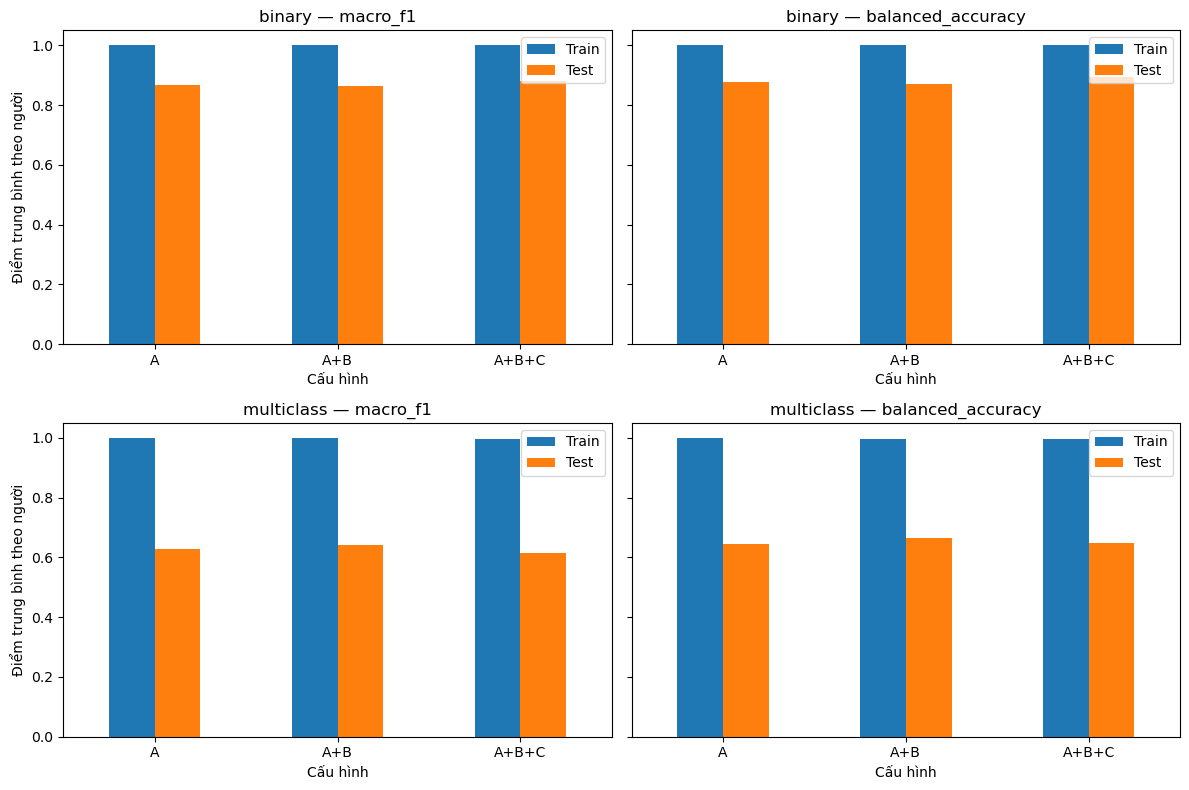

### Nhận xét điểm train–test
- multiclass, A: train Macro-F1 1.0000, test Macro-F1 0.6278, chênh lệch +0.3722.
- multiclass, A+B: train Macro-F1 0.9977, test Macro-F1 0.6414, chênh lệch +0.3563.
- multiclass, A+B+C: train Macro-F1 0.9969, test Macro-F1 0.6147, chênh lệch +0.3822.
- binary, A: train Macro-F1 1.0000, test Macro-F1 0.8678, chênh lệch +0.1322.
- binary, A+B: train Macro-F1 0.9999, test Macro-F1 0.8624, chênh lệch +0.1375.
- binary, A+B+C: train Macro-F1 0.9997, test Macro-F1 0.8813, chênh lệch +0.1184.
- binary, A+B so với A: thay đổi test Macro-F1 -0.0054, Balanced Accuracy -0.0045.
- binary, A+B+C so với A: thay đổi test Macro-F1 +0.0134, Balanced Accuracy +0.0177.
- multiclass, A+B so với A: thay đổi test Macro-F1 +0.0136, Balanced Accuracy +0.0196.
- multiclass, A+B+C so với A: thay đổi test Macro-F1 -0.0131, Balanced Accuracy +0.0032.

Điểm train cao hơn test cho thấy mô hình khớp dữ liệu đã học tốt hơn dữ liệu của người giữ riêng. Chênh lệch lớn gợi ý cần xem xét overfitting và khác biệt giữa người. Việc thêm cấu hình được đánh giá qua cả điểm test và chênh lệch train–test. Kết quả này mô tả ba cấu hình đã định trước; quy trình chọn tham số bằng inner CV thuộc EXP-009.

In [8]:
import matplotlib.pyplot as plt

verification_path = supplement_output / "verification.json"
if not verification_path.exists():
    print("Chưa có kết quả train–test cho ba cấu hình.")
else:
    check = json.loads(verification_path.read_text(encoding="utf-8"))
    assert check["status"] == "passed" and check["scope"] == "main"
    assert check["n_folds"] == 90 and check["n_test_subjects"] == 15
    train_test = pd.read_csv(supplement_output / "metrics.csv")
    order = ["A", "A+B", "A+B+C"]
    assert len(train_test) == 90
    assert not train_test.duplicated(["task", "subject_id", "stage"]).any()
    assert set(train_test["stage"]) == set(order)
    assert set(train_test["task"]) == {"binary", "multiclass"}
    assert all(
        set(rows["subject_id"]) == set(supplement_settings["expected_subjects"])
        for _, rows in train_test.groupby(["task", "stage"])
    )
    for metric in ["macro_f1", "balanced_accuracy"]:
        train_test[f"gap_{metric}"] = train_test[f"train_{metric}"] - train_test[f"test_{metric}"]
    score_columns = [
        f"{split}_{metric}" for metric in ["macro_f1", "balanced_accuracy"]
        for split in ["train", "test", "gap"]
    ]
    display(train_test.groupby(["task", "stage"])[score_columns].agg(["mean", "std"]).round(4))
    train_test.to_csv(experiment / "results_train_test.csv", index=False)

    figures = experiment / "figures"
    figures.mkdir(exist_ok=True)
    fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharey=True)
    for row, task in enumerate(["binary", "multiclass"]):
        means = train_test.loc[train_test["task"].eq(task)].groupby("stage").mean(numeric_only=True).loc[order]
        for col, metric in enumerate(["macro_f1", "balanced_accuracy"]):
            means[[f"train_{metric}", f"test_{metric}"]].rename(
                columns={f"train_{metric}": "Train", f"test_{metric}": "Test"}
            ).plot.bar(ax=axes[row, col], rot=0, title=f"{task} — {metric}")
            axes[row, col].set_ylim(0, 1.05)
            axes[row, col].set_xlabel("Cấu hình")
            axes[row, col].set_ylabel("Điểm trung bình theo người")
    fig.tight_layout()
    fig.savefig(figures / "rf_cumulative_train_test.png", dpi=150)
    plt.show()

    from IPython.display import Markdown
    paragraphs = ["### Nhận xét điểm train–test"]
    for (task, stage), rows in train_test.groupby(["task", "stage"], sort=False):
        paragraphs.append(
            f"- {task}, {stage}: train Macro-F1 {rows.train_macro_f1.mean():.4f}, "
            f"test Macro-F1 {rows.test_macro_f1.mean():.4f}, "
            f"chênh lệch {rows.gap_macro_f1.mean():+.4f}."
        )
    for task in ["binary", "multiclass"]:
        means = train_test.loc[train_test["task"].eq(task)].groupby("stage").mean(numeric_only=True)
        for stage in order[1:]:
            delta_f1 = means.loc[stage, "test_macro_f1"] - means.loc["A", "test_macro_f1"]
            delta_ba = means.loc[stage, "test_balanced_accuracy"] - means.loc["A", "test_balanced_accuracy"]
            paragraphs.append(
                f"- {task}, {stage} so với A: thay đổi test Macro-F1 {delta_f1:+.4f}, "
                f"Balanced Accuracy {delta_ba:+.4f}."
            )
    paragraphs.append(
        "\nĐiểm train cao hơn test cho thấy mô hình khớp dữ liệu đã học tốt hơn dữ liệu của người giữ riêng. "
        "Chênh lệch lớn gợi ý cần xem xét overfitting và khác biệt giữa người. "
        "Việc thêm cấu hình được đánh giá qua cả điểm test và chênh lệch train–test. "
        "Kết quả này mô tả ba cấu hình đã định trước; quy trình chọn tham số bằng inner CV thuộc EXP-009."
    )
    display(Markdown("\n".join(paragraphs)))


## Lần 4 — So sánh ba cấu hình RF với 100 cây - 22/11/2026  
Mục tiêu: xem kết quả thay đổi thế nào khi dùng 100 cây thay cho 20 cây ở lần 3. Cả ba cấu hình đều dùng 100 cây; B và C vẫn giữ ý nghĩa như lần 3.

| Cấu hình | Số cây | Độ sâu tối đa | Số đặc trưng xét tại mỗi lần chia nhánh |
| --- | --- | --- | --- |
| A | 100 | Không giới hạn | `sqrt` (căn bậc hai số đặc trưng) |
| A+B | 100 | 8 | `sqrt` |
| A+B+C | 100 | 8 | 25% số đặc trưng |

Giữ nguyên dữ liệu, 68 đặc trưng, seed 42, cách xử lý giá trị thiếu và LOSO: mỗi fold học từ 14 người, kiểm tra trên 1 người còn lại. Với 15 người, 2 bài toán và 3 cấu hình, một lượt đầy đủ có **90 fold mô hình**. Điểm train tính trên dữ liệu đã học; điểm test tính trên người giữ riêng.

Đây là so sánh các cấu hình định trước, chưa phải quy trình chọn tham số bằng inner CV. `max_features` điều khiển số đặc trưng được xét ở mỗi lần chia nhánh, không thay đổi bảng dữ liệu 68 đặc trưng.


In [9]:
from pathlib import Path
import subprocess
import json
import pandas as pd
import yaml

here100 = Path.cwd()
repo100 = next(p for p in (here100, *here100.parents) if (p / 'scripts/run_rf_train_test.py').is_file())
experiment100 = repo100 / 'experiments/01_baselines/EXP-005_RF'
config100_path = experiment100 / 'config_train_test_100.yaml'
settings100 = yaml.safe_load(config100_path.read_text(encoding='utf-8'))
output100 = repo100 / settings100['output_dir']
assert all(s['params']['n_estimators'] == 100 for s in settings100['stages'])

RUN_100_TREES = True

if RUN_100_TREES:
    subprocess.run([
        str(repo100 / '.venv-g1/Scripts/python.exe'), '-X', 'utf8',
        'scripts/run_rf_train_test.py', '--config', str(config100_path),
    ], cwd=repo100, check=True)
else:
    print('Chưa chạy huấn luyện. Đổi RUN_100_TREES = True để chạy lần 4.')

train_macro_f1         test_macro_f1         gap_macro_f1  \
                           mean     std          mean     std         mean   
task       stage                                                             
binary     A             1.0000  0.0000        0.8735  0.1440       0.1265   
           A+B           0.9999  0.0001        0.8749  0.1372       0.1250   
           A+B+C         0.9999  0.0001        0.8922  0.1366       0.1076   
multiclass A             1.0000  0.0000        0.6480  0.1297       0.3520   
           A+B           0.9986  0.0007        0.6320  0.1477       0.3666   
           A+B+C         0.9974  0.0020        0.6226  0.1430       0.3748   

                         train_balanced_accuracy          \
                     std                    mean     std   
task       stage                                           
binary     A      0.1440                  1.0000  0.0000   
           A+B    0.1372                  0.9999  0.0001   
           A+B+C  0.1366                  0.9999  0.0002   
multiclass A      0.1297                  1.0000  0.0000   
           A+B    0.1475                  0.9979  0.0010   
           A+B+C  0.1421                  0.9961  0.0031   

                 test_balanced_accuracy         gap_balanced_accuracy          
                                   mean     std                  mean     std  
task       stage                                                               
binary     A                     0.8865  0.1143                0.1135  0.1143  
           A+B                   0.8864  0.1035                0.1136  0.1036  
           A+B+C                 0.9007  0.1128                0.0992  0.1129  
multiclass A                     0.6700  0.1204                0.3300  0.1204  
           A+B                   0.6561  0.1412                0.3418  0.1407  
           A+B+C                 0.6398  0.1476                0.3563  0.1460

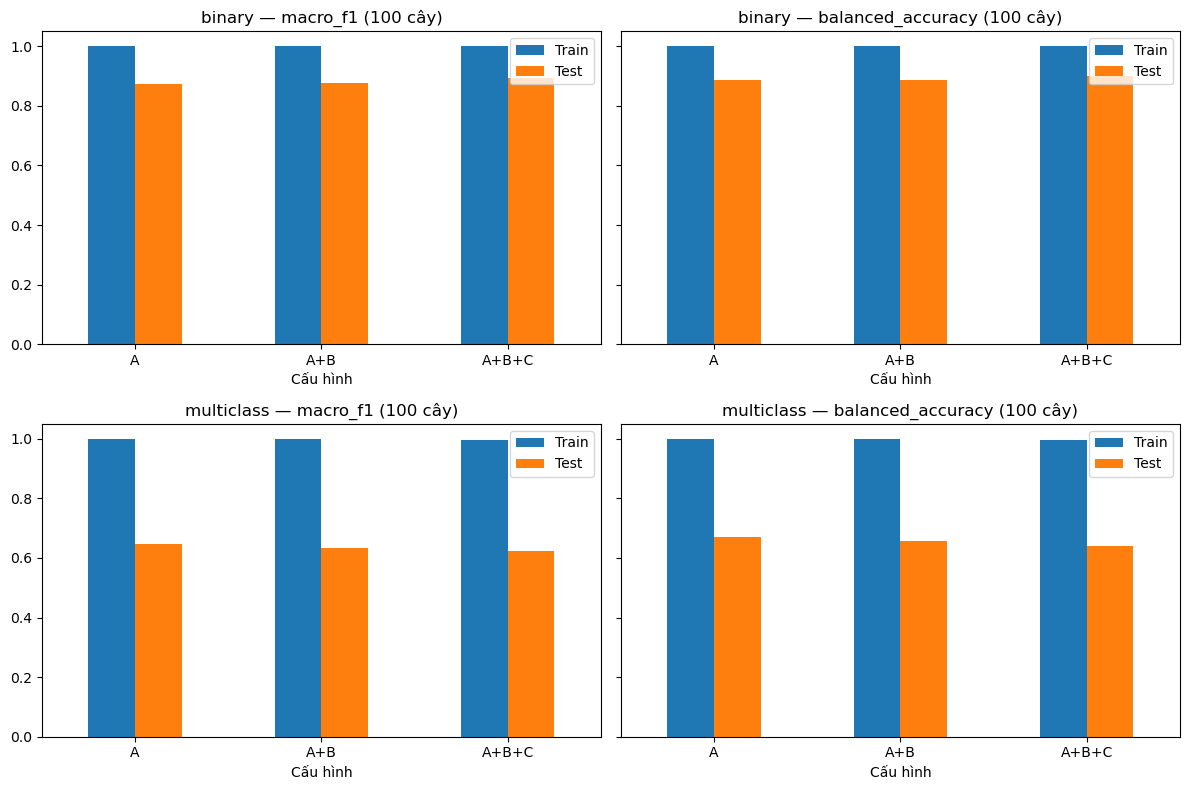

### Nhận xét lần 4: RF 100 cây
- binary, A+B so với A: test Macro-F1 thay đổi +0.0014; Balanced Accuracy -0.0001.
- binary, A+B+C so với A+B: test Macro-F1 thay đổi +0.0173; Balanced Accuracy +0.0143.
- multiclass, A+B so với A: test Macro-F1 thay đổi -0.0159; Balanced Accuracy -0.0139.
- multiclass, A+B+C so với A+B: test Macro-F1 thay đổi -0.0094; Balanced Accuracy -0.0164.
Đọc cả điểm test và khoảng cách train–test; tăng số cây không bảo đảm điểm test tăng. Các chênh lệch trên là kết quả mô tả, chưa phải kiểm định ý nghĩa thống kê.

In [10]:

verification100_path = output100 / 'verification.json'
if not verification100_path.exists():
    print('Chưa có kết quả lần 4. Chạy ô huấn luyện với RUN_100_TREES = True trước.')
else:
    from IPython.display import Markdown, display
    import matplotlib.pyplot as plt
    check100 = json.loads(verification100_path.read_text(encoding='utf-8'))
    assert check100['status'] == 'passed' and check100['scope'] == 'main'
    assert check100['n_folds'] == 90 and check100['n_test_subjects'] == 15
    scores100 = pd.read_csv(output100 / 'metrics.csv')
    order100 = ['A', 'A+B', 'A+B+C']
    assert len(scores100) == 90
    assert not scores100.duplicated(['task', 'subject_id', 'stage']).any()
    assert set(scores100.stage) == set(order100)
    assert set(scores100.task) == {'binary', 'multiclass'}
    assert all(set(rows.subject_id) == set(settings100['expected_subjects'])
               for _, rows in scores100.groupby(['task', 'stage']))
    metrics100 = ['macro_f1', 'balanced_accuracy']
    for metric in metrics100:
        scores100[f'gap_{metric}'] = scores100[f'train_{metric}'] - scores100[f'test_{metric}']
    columns100 = [f'{split}_{metric}' for metric in metrics100 for split in ['train', 'test', 'gap']]
    assert scores100[columns100].notna().all().all()
    display(scores100.groupby(['task', 'stage'])[columns100].agg(['mean', 'std']).round(4))
    scores100.to_csv(experiment100 / 'results_train_test_100.csv', index=False)

    fig100, axes100 = plt.subplots(2, 2, figsize=(12, 8), sharey=True)
    comments100 = ['### Nhận xét lần 4: RF 100 cây']
    for row, task in enumerate(['binary', 'multiclass']):
        means100 = scores100.loc[scores100.task.eq(task)].groupby('stage')[columns100].mean().loc[order100]
        for col, metric in enumerate(metrics100):
            means100[[f'train_{metric}', f'test_{metric}']].rename(
                columns={f'train_{metric}': 'Train', f'test_{metric}': 'Test'}
            ).plot.bar(ax=axes100[row, col], rot=0, title=f'{task} — {metric} (100 cây)')
            axes100[row, col].set_ylim(0, 1.05)
            axes100[row, col].set_xlabel('Cấu hình')
        for previous, current in zip(order100, order100[1:]):
            delta100 = means100.loc[current] - means100.loc[previous]
            comments100.append(
                f'- {task}, {current} so với {previous}: test Macro-F1 thay đổi '
                f'{delta100.test_macro_f1:+.4f}; Balanced Accuracy '
                f'{delta100.test_balanced_accuracy:+.4f}.'
            )
    fig100.tight_layout()
    (experiment100 / 'figures').mkdir(exist_ok=True)
    fig100.savefig(experiment100 / 'figures/rf_cumulative_train_test_100.png', dpi=150)
    plt.show()
    comments100.append('Đọc cả điểm test và khoảng cách train–test; tăng số cây không bảo đảm điểm test tăng. Các chênh lệch trên là kết quả mô tả, chưa phải kiểm định ý nghĩa thống kê.')
    display(Markdown('\n'.join(comments100)))